<a href="https://colab.research.google.com/github/fernandyan/MyGoogleColab/blob/main/fernand_flask2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import

In [854]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, Normalizer, StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier # rfC- 0.7412, gbc-0.721875, abc - 0.4834
from sklearn.neighbors import KNeighborsClassifier # 2 - 0.6112
from sklearn.tree import DecisionTreeClassifier # 2 - 0.64875
from sklearn.svm import SVC # 1 - 0.8175
from sklearn.naive_bayes import GaussianNB

from sklearn.linear_model import LinearRegression # 0.4909528790305868
from sklearn.ensemble import RandomForestRegressor # 0.854639819213566
from sklearn.tree import DecisionTreeRegressor # 0.7812665091285166
from sklearn.svm import SVR # 0.723410803475629

# fast food

In [ ]:
df = pd.read_csv("/content/fast_food_cheat_meal_workout_burn.csv")

In [ ]:
df.head(3)

,order_id,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,...,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,FFC-00001,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,...,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,FFC-00002,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,...,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,FFC-00003,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,...,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll


In [ ]:
df.columns

Index(['order_id', 'fast_food_chain', 'meal_category', 'item_count',
       'total_calories', 'fat_grams', 'saturated_fat_grams', 'carb_grams',
       'sugar_grams', 'protein_grams', 'sodium_mg', 'consumer_gender',
       'consumer_age', 'consumer_weight_kg', 'fitness_level',
       'thermic_effect_calories', 'net_caloric_surplus',
       'walking_burn_time_min', 'cycling_burn_time_min',
       'running_burn_time_min', 'hiit_burn_time_min',
       'daily_calorie_allowance_pct', 'workout_shock_tier'],
      dtype='object')

In [ ]:
df['total_calories'].unique()

array([1015, 1849, 1920, ..., 2408, 2818, 2891])

In [ ]:
df.isnull().sum()

,0
order_id,0
fast_food_chain,0
meal_category,0
item_count,0
total_calories,0
fat_grams,0
saturated_fat_grams,0
carb_grams,0
sugar_grams,0
protein_grams,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   order_id                     8000 non-null   object 
 1   fast_food_chain              8000 non-null   object 
 2   meal_category                8000 non-null   object 
 3   item_count                   8000 non-null   int64  
 4   total_calories               8000 non-null   int64  
 5   fat_grams                    8000 non-null   int64  
 6   saturated_fat_grams          8000 non-null   int64  
 7   carb_grams                   8000 non-null   int64  
 8   sugar_grams                  8000 non-null   int64  
 9   protein_grams                8000 non-null   int64  
 10  sodium_mg                    8000 non-null   int64  
 11  consumer_gender              8000 non-null   object 
 12  consumer_age                 8000 non-null   int64  
 13  consumer_weight_kg

In [ ]:
X = df.drop(columns=['workout_shock_tier','order_id'])
y = df['workout_shock_tier']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X.head()

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,...,consumer_age,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,...,61,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,...,65,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,...,35,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,...,61,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,...,19,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2


## pipeline e columntransformer

In [ ]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(include="object").columns

In [ ]:
# 1. Definir os transformadores para cada tipo de coluna
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
    # ('scaler', MinMaxScaler())
    # ('scaler', Normalizer())
])

In [ ]:
# 1. Definir os transformadores para cada tipo de coluna
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='error')),
    # ('scaler', MinMaxScaler())
    ('scaler', StandardScaler())
    # ('scaler', Normalizer())
])

In [ ]:
# 2. Criar o ColumnTransformer para processar as colunas em paralelo
preprocessor = ColumnTransformer(
    transformers=[
        # ('num', num_transformer, ['idade', 'salario']),
        ('n', num_transformer, num_cols),
        # ('cat', cat_transformer, ['cidade', 'genero'])
        ('c', cat_transformer, cat_cols)
    ],
    remainder='passthrough' # Mantém colunas não listadas (opcional)
)

In [ ]:
# 3. Criar o Pipeline final que inclui o pré-processamento e o modelo
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    # ('classifier', SVC())
    ('classifier', RandomForestClassifier())
])

In [ ]:
# transform in pandas
preprocessor.set_output(transform="pandas")

ColumnTransformer(remainder='passthrough',
                  transformers=[('n',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['item_count', 'total_calories', 'fat_grams', 'saturated_fat_grams',
       'carb_grams', 'sugar_grams', 'protein_grams', 'sodium_mg',
       'consumer_age', 'consumer_weight_kg', 'thermic_effect_calories',
       'net_calor...e_min', 'cycling_burn_time_min',
       'running_burn_time_min', 'hiit_burn_time_min',
       'daily_calorie_allowance_pct'],
      dtype='object')),
                                ('c',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder', OrdinalEncoder()),
                                                 ('scaler', StandardScaler())]),
                                 Index(['fast_food_chain', 'meal_category', 'consumer_gender', 'fitness_level'], dtype='object'))])

In [ ]:
df_pre = preprocessor.fit_transform(X)
df_pre

,n__item_count,n__total_calories,n__fat_grams,n__saturated_fat_grams,n__carb_grams,n__sugar_grams,n__protein_grams,n__sodium_mg,n__consumer_age,n__consumer_weight_kg,...,n__net_caloric_surplus,n__walking_burn_time_min,n__cycling_burn_time_min,n__running_burn_time_min,n__hiit_burn_time_min,n__daily_calorie_allowance_pct,c__fast_food_chain,c__meal_category,c__consumer_gender,c__fitness_level
0,-0.448756,-0.874255,-0.964268,-0.901709,-0.691682,-0.228061,-0.718097,-0.715488,1.400937,1.306343,...,-0.873389,-1.105779,-1.086452,-1.040177,-1.142217,-0.875734,0.007449,0.279588,0.929714,-0.422759
1,1.338672,0.366658,0.669028,0.001033,0.000546,-0.039340,0.357228,0.378899,1.688049,-1.737773,...,0.371377,1.219459,1.246542,1.217962,1.282405,0.365172,1.111010,-0.308709,-1.075600,-0.422759
2,-1.342470,0.472299,0.756526,1.250984,0.254834,-0.039340,0.096543,-0.258716,-0.465292,-0.775718,...,0.488114,0.691659,0.702306,0.718756,0.647687,0.472301,-1.096112,1.456184,-1.075600,-0.422759
3,-1.342470,-0.517158,-0.380948,-0.485059,-0.437395,-0.636955,-0.881024,-0.481509,1.400937,-1.091616,...,-0.495078,0.005155,0.018787,0.042936,0.061631,-0.518638,0.007449,-1.485304,-1.075600,0.974792
4,0.444958,0.092883,0.231538,0.001033,-0.154852,0.212287,0.259471,-0.088126,-1.613740,-0.344946,...,0.090855,0.067785,0.075532,0.021310,0.093367,0.091399,1.111010,-0.897007,0.929714,-0.422759
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,-1.342470,0.237210,0.114874,-0.207292,0.057054,0.463914,0.911182,0.596099,-1.541962,-0.409562,...,0.207913,0.042247,0.044580,-0.014734,0.008738,0.237213,-1.463966,-0.308709,0.929714,-1.820310
7996,-0.448756,1.808437,2.098162,1.737075,2.260882,0.809901,-0.555169,1.806077,-1.183072,1.981218,...,1.875951,0.748209,0.779686,0.731372,0.668844,1.808432,0.743156,-0.308709,0.929714,0.974792
7997,1.338672,-0.539476,-0.497612,-0.346176,-0.564538,-0.448234,-0.359655,-0.598032,1.042046,2.663273,...,-0.539075,-0.956803,-1.078714,-0.915827,-1.013157,-0.539469,1.478864,1.456184,0.929714,0.974792
7998,0.444958,0.330948,-0.060122,-0.346176,0.184198,0.778448,1.562894,0.503812,0.467822,-1.831107,...,0.274069,1.195137,1.213011,1.122446,1.098337,0.329463,-0.360405,-0.308709,-1.075600,-0.422759


<Axes: >

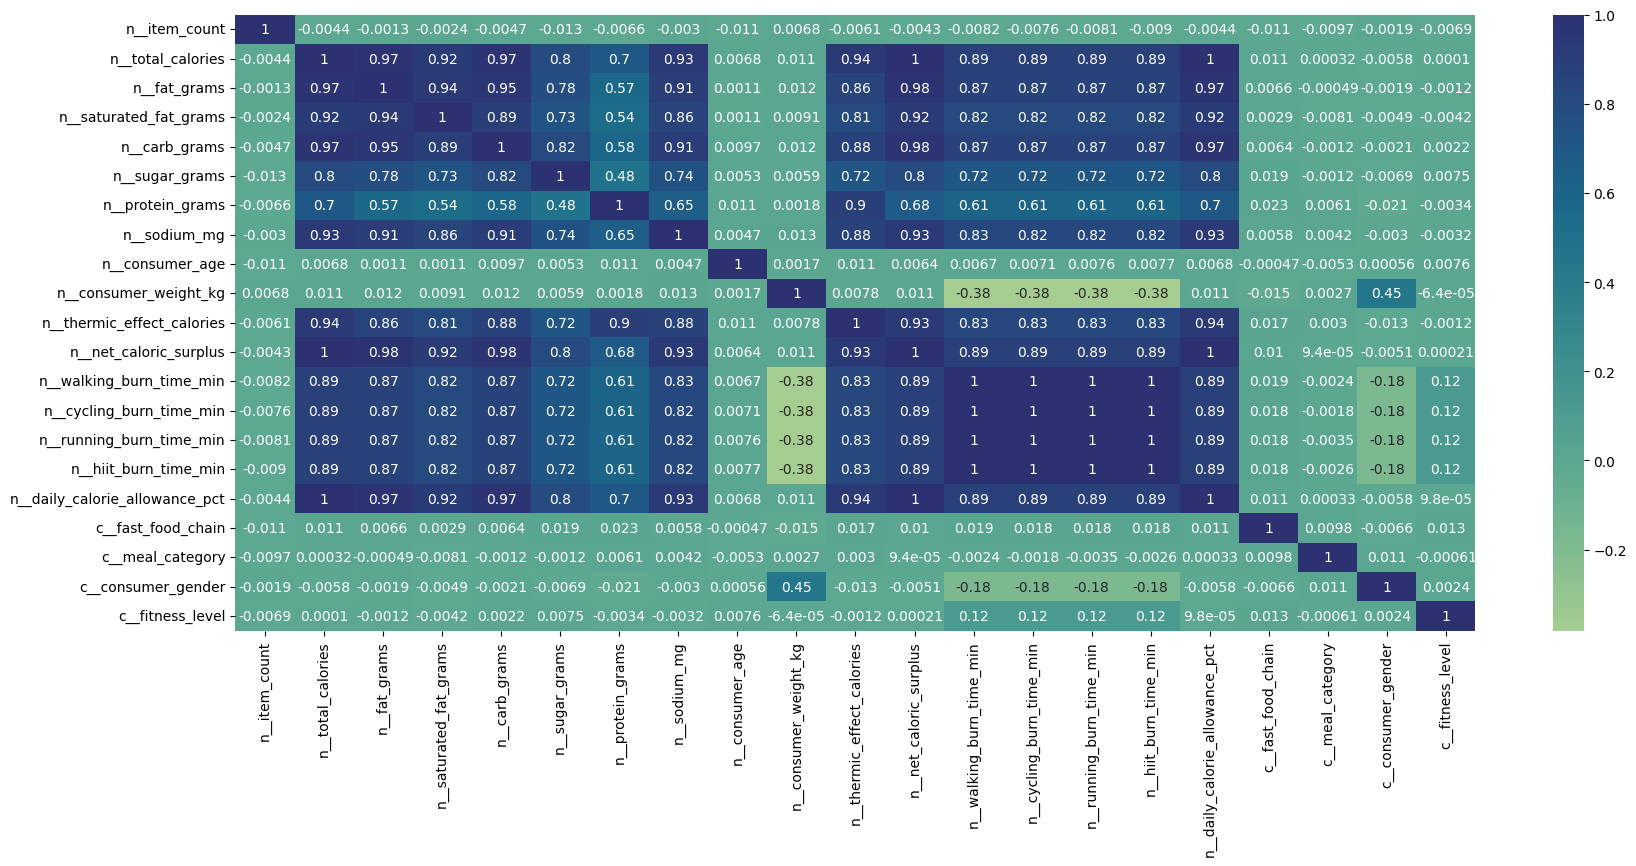

In [ ]:
plt.figure(figsize=(20, 8))
sns.heatmap(df_pre.corr(), annot=True, cmap="crest")

In [ ]:
clf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('n',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['item_count', 'total_calories', 'fat_grams', 'saturated_fat_grams',
       'carb_grams', 'sugar_grams', 'protein_grams', 'sodium_mg',
       'consumer_age', 'consumer_weight_kg', 'the...
       'running_burn_time_min', 'hiit_burn_time_min',
       'daily_calorie_allowance_pct'],
      dtype='object')),
                                                 ('c',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['fast_food_chain', 'meal_category', 'consumer_gender', 'fitness_level'], dtype='object'))])),
                ('classifier', RandomForestClassifier())])

In [ ]:
clf.score(X_test, y_test)

0.999375

## cross val data

In [ ]:
df_pre.head()

,n__item_count,n__total_calories,n__fat_grams,n__saturated_fat_grams,n__carb_grams,n__sugar_grams,n__protein_grams,n__sodium_mg,n__consumer_age,n__consumer_weight_kg,...,n__net_caloric_surplus,n__walking_burn_time_min,n__cycling_burn_time_min,n__running_burn_time_min,n__hiit_burn_time_min,n__daily_calorie_allowance_pct,c__fast_food_chain,c__meal_category,c__consumer_gender,c__fitness_level
0,-0.448756,-0.874255,-0.964268,-0.901709,-0.691682,-0.228061,-0.718097,-0.715488,1.400937,1.306343,...,-0.873389,-1.105779,-1.086452,-1.040177,-1.142217,-0.875734,0.007449,0.279588,0.929714,-0.422759
1,1.338672,0.366658,0.669028,0.001033,0.000546,-0.039340,0.357228,0.378899,1.688049,-1.737773,...,0.371377,1.219459,1.246542,1.217962,1.282405,0.365172,1.111010,-0.308709,-1.075600,-0.422759
2,-1.342470,0.472299,0.756526,1.250984,0.254834,-0.039340,0.096543,-0.258716,-0.465292,-0.775718,...,0.488114,0.691659,0.702306,0.718756,0.647687,0.472301,-1.096112,1.456184,-1.075600,-0.422759
3,-1.342470,-0.517158,-0.380948,-0.485059,-0.437395,-0.636955,-0.881024,-0.481509,1.400937,-1.091616,...,-0.495078,0.005155,0.018787,0.042936,0.061631,-0.518638,0.007449,-1.485304,-1.075600,0.974792
4,0.444958,0.092883,0.231538,0.001033,-0.154852,0.212287,0.259471,-0.088126,-1.613740,-0.344946,...,0.090855,0.067785,0.075532,0.021310,0.093367,0.091399,1.111010,-0.897007,0.929714,-0.422759


In [ ]:
cross_val_data = cross_val_score(clf, X, y, cv=5, scoring="accuracy")


In [ ]:
cross_val_data

array([1.      , 1.      , 0.999375, 1.      , 1.      ])

In [ ]:
cross_val_data.mean()

np.float64(0.9998750000000001)

## my sns and pipeline other

In [ ]:
#sns.pairplot(X.sample(100))

<Axes: >

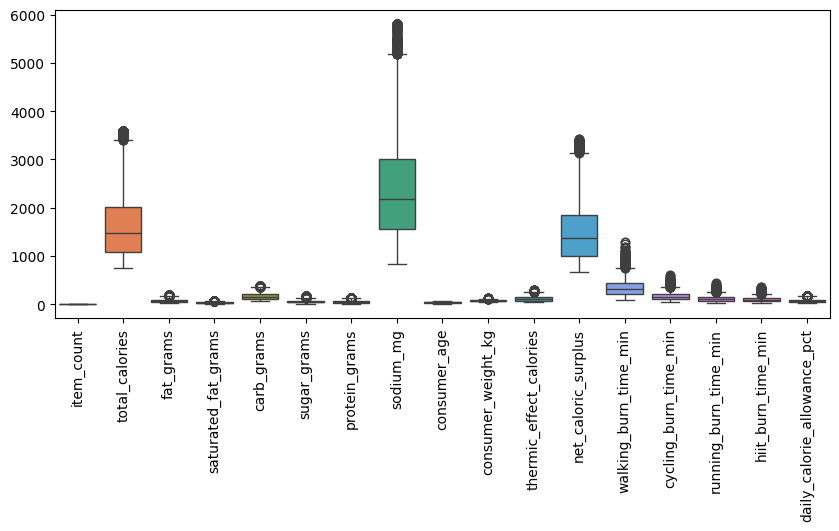

In [ ]:
plt.figure(figsize=(10, 4))
plt.xticks(rotation='vertical')  # ou rotation=90
sns.boxplot(X)

In [ ]:
#sns.heatmap(X.corr(), annot=True, cmap="crest")

In [ ]:
pipeline_mode = Pipeline([
    ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
    ('normalizer', Normalizer()),
    ('simpleImputer', SimpleImputer()),
    ('classifier', SVC()),
])
pipeline_mode

Pipeline(steps=[('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
                ('normalizer', Normalizer()),
                ('simpleImputer', SimpleImputer()), ('classifier', SVC())])

In [ ]:
pipeline_mode.fit(X_train, y_train)

Pipeline(steps=[('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
                ('normalizer', Normalizer()),
                ('simpleImputer', SimpleImputer()), ('classifier', SVC())])

In [ ]:
pipeline_mode.score(X_test, y_test)

0.8175

## value_count

In [ ]:
y.unique()

array(['High Sweat Penalty', 'Extreme / Half-Marathon Toll',
       'Severe Cardio Deficit', 'Moderate Burn'], dtype=object)

In [ ]:
y.value_counts()

,count
workout_shock_tier,
Extreme / Half-Marathon Toll,3257
Severe Cardio Deficit,2429
High Sweat Penalty,2122
Moderate Burn,192


In [ ]:
y.value_counts(normalize=True)

,proportion
workout_shock_tier,
Extreme / Half-Marathon Toll,0.407125
Severe Cardio Deficit,0.303625
High Sweat Penalty,0.265250
Moderate Burn,0.024000


# car price

In [855]:
df = pd.read_csv("https://raw.githubusercontent.com/sagnikghoshcr7/Car-Price-Prediction/refs/heads/master/data/dataset.csv")

In [856]:
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [857]:
df.columns

Index(['Unnamed: 0', 'Name', 'Location', 'Year', 'Kilometers_Driven',
       'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power',
       'Seats', 'New_Price', 'Price'],
      dtype='object')

In [858]:
df.shape

(6019, 14)

In [859]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   object 
 2   Location           6019 non-null   object 
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   object 
 6   Transmission       6019 non-null   object 
 7   Owner_Type         6019 non-null   object 
 8   Mileage            6017 non-null   object 
 9   Engine             5983 non-null   object 
 10  Power              5983 non-null   object 
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    object 
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), object(9)
memory usage: 658.5+ KB


In [860]:
# 1. Remove 'km' and spaces, replace the thousands separator with nothing, and replace the decimal comma with a decimal point
df['Mileage'] = (
    df['Mileage']
    .str.replace(' km/kg', '', regex=False)
    .str.replace(' kmpl', '', regex=False)  # Remove o ponto de milhar
    .str.replace(',', '.', regex=False)  # Troca a vírgula decimal por ponto
    .str.strip()
)
# 2. Convert to float
df['Mileage'] = pd.to_numeric(df['Mileage'])

In [861]:
# 1. Remove 'km' and spaces, replace the thousands separator with nothing, and replace the decimal comma with a decimal point
df['New_Price'] = (
    df['New_Price']
    .str.replace(' Lakh', '', regex=False)
    .str.replace(' Cr', '', regex=False)  # Remove o ponto de milhar
    .str.replace(',', '.', regex=False)  # Troca a vírgula decimal por ponto
    .str.strip()
)
# 2. Convert to float
df['New_Price'] = pd.to_numeric(df['New_Price'])

In [862]:
# 1. Remove 'km' and spaces, replace the thousands separator with nothing, and replace the decimal comma with a decimal point
df['Engine'] = (
    df['Engine']
    .str.replace(' CC', '', regex=False)
    .str.replace(' Cr', '', regex=False)  # Remove o ponto de milhar
    .str.replace(',', '.', regex=False)  # Troca a vírgula decimal por ponto
    .str.strip()
)
# 2. Convert to float
df['Engine'] = pd.to_numeric(df['Engine'])

In [863]:
# 1. Remove 'km' and spaces, replace the thousands separator with nothing, and replace the decimal comma with a decimal point
df['Power'] = (
    df['Power']
    .str.replace(' bhp', '', regex=False)
    .str.replace(' Cr', '', regex=False)  # Remove o ponto de milhar
    .str.replace(',', '.', regex=False)  # Troca a vírgula decimal por ponto
    .str.strip()
)
# 2. Convert to float
df['Power'] = pd.to_numeric(df['Power'], errors='coerce')

In [864]:
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.60,998.0,58.16,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67,1582.0,126.20,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.20,1199.0,88.70,5.0,8.61,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77,1248.0,88.76,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.20,1968.0,140.80,5.0,NaN,17.74


In [865]:
df.isnull().sum()

,0
Unnamed: 0,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,2
Engine,36


In [866]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   object 
 2   Location           6019 non-null   object 
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   object 
 6   Transmission       6019 non-null   object 
 7   Owner_Type         6019 non-null   object 
 8   Mileage            6017 non-null   float64
 9   Engine             5983 non-null   float64
 10  Power              5876 non-null   float64
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    float64
 13  Price              6019 non-null   float64
dtypes: float64(6), int64(3), object(5)
memory usage: 658.5+ KB


## Preprocesser X, y

In [867]:
X = df.drop(columns=['Unnamed: 0','Price','Name'])
y = df['Price']

In [868]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(include="object").columns

In [869]:
# 1. Define the transformers for each type of column
number_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [870]:
# 1. Define the transformers for each type of column
category_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ('scaler', StandardScaler())
])

In [871]:
# 2. Create the ColumnTransformer to process the columns in parallel
CT_preprocessor = ColumnTransformer(
    transformers=[
        ('n', number_transformer, num_cols),
        ('c', category_transformer, cat_cols)
    ],
    remainder='passthrough' # Keep unlisted columns (optional)
)

In [872]:
# 3. Criar o Pipeline final que inclui o pré-processamento e o modelo
classifier_mode = Pipeline(steps=[
    ('preprocessor', CT_preprocessor),
    ('classifier', RandomForestRegressor())
])
classifier_mode

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('n',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats',
       'New_Price'],
      dtype='object')),
                                                 ('c',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Location', 'Fuel_Type', 'Transmission', 'Owner_Type'], dtype='object'))])),
                ('classifier', RandomForestRegressor())])

In [873]:
# transform in pandas
CT_preprocessor.set_output(transform="pandas")

ColumnTransformer(remainder='passthrough',
                  transformers=[('n',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats',
       'New_Price'],
      dtype='object')),
                                ('c',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 unknown_value=-1)),
                                                 ('scaler', StandardScaler())]),
                                 Index(['Location', 'Fuel_Type', 'Transmission', 'Owner_Type'], dtype='object'))])

In [874]:
df_pre = CT_preprocessor.fit_transform(X)
df_pre

,n__Year,n__Kilometers_Driven,n__Mileage,n__Engine,n__Power,n__Seats,n__New_Price,c__Location,c__Fuel_Type,c__Transmission,c__Owner_Type
0,-1.027139,0.145315,1.847798,-1.038232,-1.027107,-0.343293,-0.151043,1.143658,-1.570306,0.632529,-0.463672
1,0.502161,-0.194369,0.335076,-0.064226,0.249937,-0.343293,-0.151043,1.481989,-0.905771,0.632529,-0.463672
2,-0.721279,-0.139581,0.014196,-0.703001,-0.453901,-0.343293,-0.498550,-1.224657,1.087831,0.632529,-0.463672
3,-0.415419,0.309678,0.575191,-0.621278,-0.452775,2.137237,-0.151043,-1.224657,-0.905771,0.632529,-0.463672
4,-0.109559,-0.197985,-0.640662,0.579552,0.523965,-0.343293,-0.151043,-0.886327,-0.905771,-1.580955,1.980149
...,...,...,...,...,...,...,...,...,...,...,...
6014,0.196301,-0.343775,2.240713,-0.621278,-0.729806,-0.343293,-0.588989,-0.547996,-0.905771,0.632529,-0.463672
6015,0.502161,0.452126,1.367569,-0.834759,-0.786113,-0.343293,-0.151043,0.128666,-0.905771,0.632529,-0.463672
6016,-0.415419,-0.040963,-0.902605,1.463495,-0.016583,3.377503,-0.151043,0.128666,-0.905771,0.632529,1.980149
6017,-0.109559,-0.139581,0.166996,-1.038232,-0.859312,-0.343293,-0.151043,0.805327,1.087831,0.632529,-0.463672


## Graphics

<Axes: >

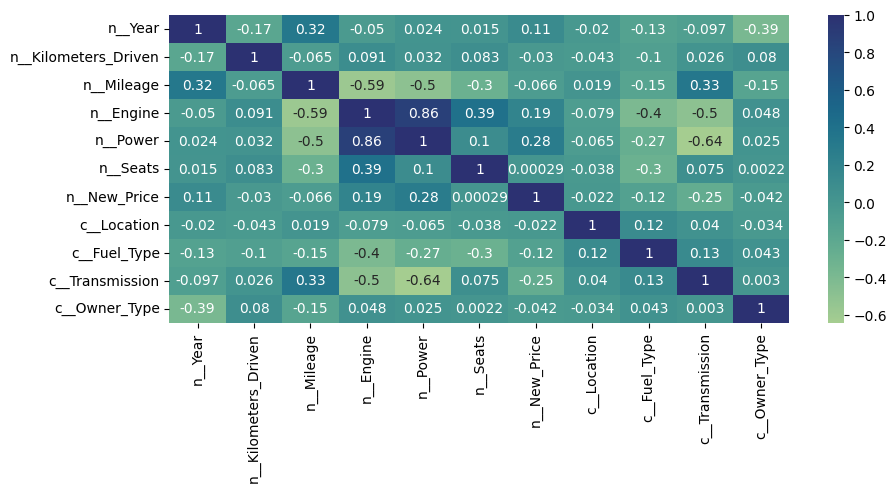

In [875]:
plt.figure(figsize=(10, 4))
sns.heatmap(df_pre.corr(), annot=True, cmap="crest")

<Axes: >

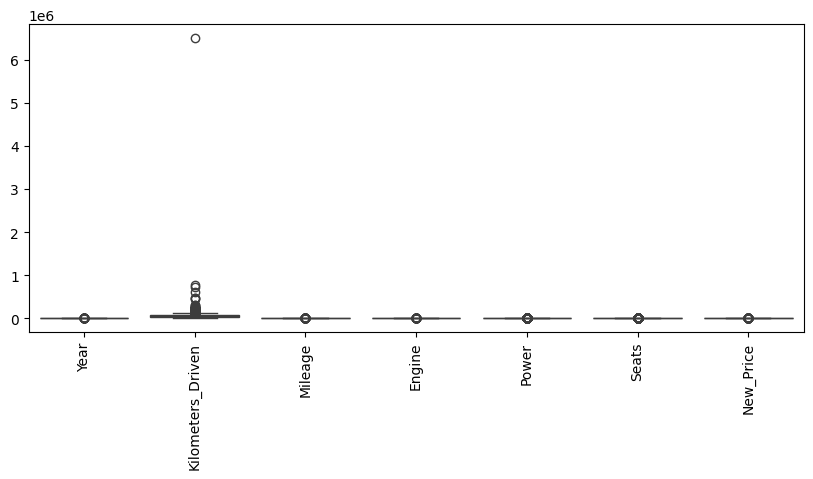

In [876]:
plt.figure(figsize=(10, 4))
plt.xticks(rotation='vertical')  # ou rotation=90
sns.boxplot(X)

In [877]:
# plt.figure(figsize=(0.1, 0.1))
# sns.pairplot(X.sample(100))

## fit & cross val data

In [878]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [879]:
classifier_mode.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('n',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats',
       'New_Price'],
      dtype='object')),
                                                 ('c',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Location', 'Fuel_Type', 'Transmission', 'Owner_Type'], dtype='object'))])),
                ('classifier', RandomForestRegressor())])

In [880]:
# Execute as células anteriores que definem o pipeline e o fit antes de rodar esta célula
classifier_mode.score(X_test, y_test)

0.8604099927075589

In [881]:
classifier_mode.n_features_in_

11

In [882]:
classifier_mode.feature_names_in_

array(['Location', 'Year', 'Kilometers_Driven', 'Fuel_Type',
       'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power',
       'Seats', 'New_Price'], dtype=object)